# Corewell Health: Multi-Objective Hospital Staffing Optimization
**Phase 1 — Optimization Engine**

**Research question:** Among 100 illustrative staffing scenarios, which combinations minimize estimated labor costs while maximizing a modeled patient-safety proxy?

**Important:** This is an educational model using synthetic scenarios, not actual Corewell Health staffing or patient-outcome data. The safety score is an invented proxy, **not a clinically validated measure**. No operational or clinical decisions should be made from these outputs.

## 1. Setup and data acquisition
The dataset was generated using a deterministic Python script with seed 42. Each row represents a hypothetical 12-hour staffing shift. Regular nurse cost = $48/hour, overtime = $72/hour, and agency = $95/hour, **illustrative assumptions rather than verified Corewell Health rates**. Required nursing hours range from 70–110. Safety proxy increases with coverage and includes penalties for overtime and agency reliance. All ranges and coefficients require external validation before any real use.

**LLM generation prompt documentation:** “Generate 100 reproducible synthetic hospital staffing scenarios for a classroom multi-objective optimization exercise, with regular/overtime/agency nurses, 12-hour shifts, demand hours, modeled costs, and a clearly labeled unvalidated safety proxy. Use fixed random seed 42; do not represent figures as actual Corewell Health data.”

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
DATA = Path('data/staffing_scenarios.csv')
OUT = Path('images'); OUT.mkdir(exist_ok=True)
df = pd.read_csv(DATA)
print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (100, 8)


,scenario_id,regular_nurses,overtime_nurses,agency_nurses,required_nursing_hours,available_nursing_hours,staffing_cost_usd,safety_proxy_score
0,1,7,5,3,87,180,11772,83.31
1,2,10,6,0,98,192,10944,83.17
2,3,8,0,3,110,132,8028,76.59
3,4,13,5,4,102,264,16368,85.42
4,5,11,0,5,88,192,12036,90.14


## 2. Validate and explore the data

In [2]:
assert 50 <= len(df) <= 150
assert df.scenario_id.is_unique
assert not df.isna().any().any()
assert (df[['regular_nurses','overtime_nurses','agency_nurses','required_nursing_hours','available_nursing_hours','staffing_cost_usd']] >= 0).all().all()
assert df.safety_proxy_score.between(0,100).all()
assert np.allclose(df.available_nursing_hours,12*(df.regular_nurses+df.overtime_nurses+df.agency_nurses))
assert np.allclose(df.staffing_cost_usd,12*(48*df.regular_nurses+72*df.overtime_nurses+95*df.agency_nurses))
print('Missing values:', df.isna().sum().sum())
print('Duplicates:', df.duplicated().sum())
display(df.describe().round(2))

Missing values: 0
Duplicates: 0


,scenario_id,regular_nurses,overtime_nurses,agency_nurses,required_nursing_hours,available_nursing_hours,staffing_cost_usd,safety_proxy_score
count,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
mean,50.50,11.01,2.83,2.46,90.69,195.60,11591.28,86.07
std,29.01,2.68,1.94,1.60,11.90,40.45,2627.55,4.48
min,1.00,7.00,0.00,0.00,70.00,84.00,4032.00,65.01
25%,25.75,9.00,1.00,1.00,81.00,168.00,10296.00,83.73
50%,50.50,11.00,3.00,2.00,91.00,192.00,11508.00,87.40
75%,75.25,13.25,5.00,4.00,101.00,228.00,13497.00,89.12
max,100.00,15.00,6.00,5.00,110.00,276.00,17508.00,93.82


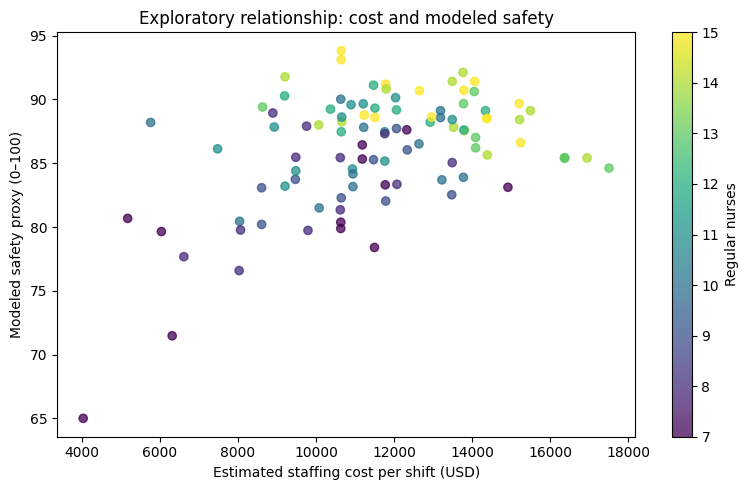

In [3]:
fig, ax = plt.subplots(figsize=(8,5))
sc=ax.scatter(df.staffing_cost_usd,df.safety_proxy_score,c=df.regular_nurses,cmap='viridis',alpha=.75)
ax.set(xlabel='Estimated staffing cost per shift (USD)',ylabel='Modeled safety proxy (0–100)',title='Exploratory relationship: cost and modeled safety')
fig.colorbar(sc,ax=ax,label='Regular nurses');fig.tight_layout();fig.savefig(OUT/'exploratory_scatter.png',dpi=180);plt.show()

## 3. Calculate Pareto frontier
A scenario is dominated if another scenario costs **no more** and has a safety proxy **no lower**, with at least one strict improvement. This definition handles ties correctly.

In [4]:
def pareto_efficient(cost, safety):
    cost=np.asarray(cost,dtype=float); safety=np.asarray(safety,dtype=float)
    efficient=np.ones(len(cost),dtype=bool)
    for i in range(len(cost)):
        dominates=(cost<=cost[i]) & (safety>=safety[i]) & ((cost<cost[i]) | (safety>safety[i]))
        efficient[i]=not np.any(dominates)
    return efficient

df['pareto_efficient']=pareto_efficient(df.staffing_cost_usd,df.safety_proxy_score)
front=df[df.pareto_efficient].copy().sort_values('staffing_cost_usd')
dominated=df[~df.pareto_efficient].copy()
print(f'Efficient: {len(front)} / {len(df)}; Dominated: {len(dominated)} / {len(df)}')
assert len(front)+len(dominated)==len(df)
display(front[['scenario_id','staffing_cost_usd','safety_proxy_score']])

Efficient: 7 / 100; Dominated: 93 / 100


,scenario_id,staffing_cost_usd,safety_proxy_score
96,97,4032,65.01
29,30,5172,80.68
42,43,5760,88.20
64,65,8628,89.41
34,35,9192,90.28
62,63,9204,91.77
81,82,10644,93.82


## 4. Examples of dominated solutions and better alternatives

In [5]:
examples=[]
for _, r in dominated.head(5).iterrows():
    better=front[(front.staffing_cost_usd<=r.staffing_cost_usd)&(front.safety_proxy_score>=r.safety_proxy_score)]
    if len(better):
        b=better.sort_values(['staffing_cost_usd','safety_proxy_score'],ascending=[True,False]).iloc[0]
        examples.append({'dominated_id':int(r.scenario_id),'efficient_id':int(b.scenario_id),
                         'cost_saved_usd':round(r.staffing_cost_usd-b.staffing_cost_usd,2),
                         'safety_proxy_gain':round(b.safety_proxy_score-r.safety_proxy_score,2)})
display(pd.DataFrame(examples))
if len(dominated):
    # A 'best dominated' and 'worst frontier' comparison is ambiguous in two dimensions.
    # Here 'best' and 'worst' mean normalized equal-weight utility, not Pareto dominance.
    def utility(frame):
        cr=df.staffing_cost_usd.max()-df.staffing_cost_usd.min()
        sr=df.safety_proxy_score.max()-df.safety_proxy_score.min()
        return .5*(df.staffing_cost_usd.max()-frame.staffing_cost_usd)/(cr or 1)+.5*(frame.safety_proxy_score-df.safety_proxy_score.min())/(sr or 1)
    best_dom=dominated.loc[utility(dominated).idxmax()]
    worst_front=front.loc[utility(front).idxmin()]
    display(pd.DataFrame([best_dom,worst_front])[['scenario_id','staffing_cost_usd','safety_proxy_score','pareto_efficient']])
    print('These are compared by equal-weight utility; neither is necessarily dominant over the other.')

,dominated_id,efficient_id,cost_saved_usd,safety_proxy_gain
0,1,43,6012,4.89
1,2,43,5184,5.03
2,3,30,2856,4.09
3,4,43,10608,2.78
4,5,35,2844,0.14


,scenario_id,staffing_cost_usd,safety_proxy_score,pareto_efficient
35,36,10644,93.12,False
96,97,4032,65.01,True


These are compared by equal-weight utility; neither is necessarily dominant over the other.


## 5. Five strategic points
For comparability, normalize each objective over **all 100 scenarios**. Balanced maximizes the sum of normalized cost efficiency and safety. Equity minimizes the absolute gap between the two normalized objective scores (a fairness *between objectives*, not patient-group equity). Cost priority minimizes cost. Safety priority maximizes safety. Custom strategy gives safety 60% and cost 40%. All selections are restricted to the Pareto frontier.

In [6]:
cost_span=df.staffing_cost_usd.max()-df.staffing_cost_usd.min()
safety_span=df.safety_proxy_score.max()-df.safety_proxy_score.min()
front['cost_score']=(df.staffing_cost_usd.max()-front.staffing_cost_usd)/(cost_span or 1)
front['safety_score']=(front.safety_proxy_score-df.safety_proxy_score.min())/(safety_span or 1)
strategies={
    'Balanced':front.loc[(front.cost_score+front.safety_score).idxmax()],
    'Equity (objective balance)':front.loc[(front.cost_score-front.safety_score).abs().idxmin()],
    'Cost priority':front.loc[front.staffing_cost_usd.idxmin()],
    'Safety priority':front.loc[front.safety_proxy_score.idxmax()],
    'Custom: 60% safety':front.loc[(.4*front.cost_score+.6*front.safety_score).idxmax()]
}
cols=['scenario_id','regular_nurses','overtime_nurses','agency_nurses','staffing_cost_usd','safety_proxy_score']
comparison=pd.DataFrame({k:v[cols] for k,v in strategies.items()}).T
comparison.index.name='strategy'; display(comparison)
comparison.to_csv('data/strategy_comparison.csv')

,scenario_id,regular_nurses,overtime_nurses,agency_nurses,staffing_cost_usd,safety_proxy_score
strategy,,,,,,
Balanced,43,10,0,0,5760,88.2
Equity (objective balance),43,10,0,0,5760,88.2
Cost priority,97,7,0,0,4032,65.01
Safety priority,82,15,1,1,10644,93.82
Custom: 60% safety,43,10,0,0,5760,88.2


## 6. Executive-ready visualizations

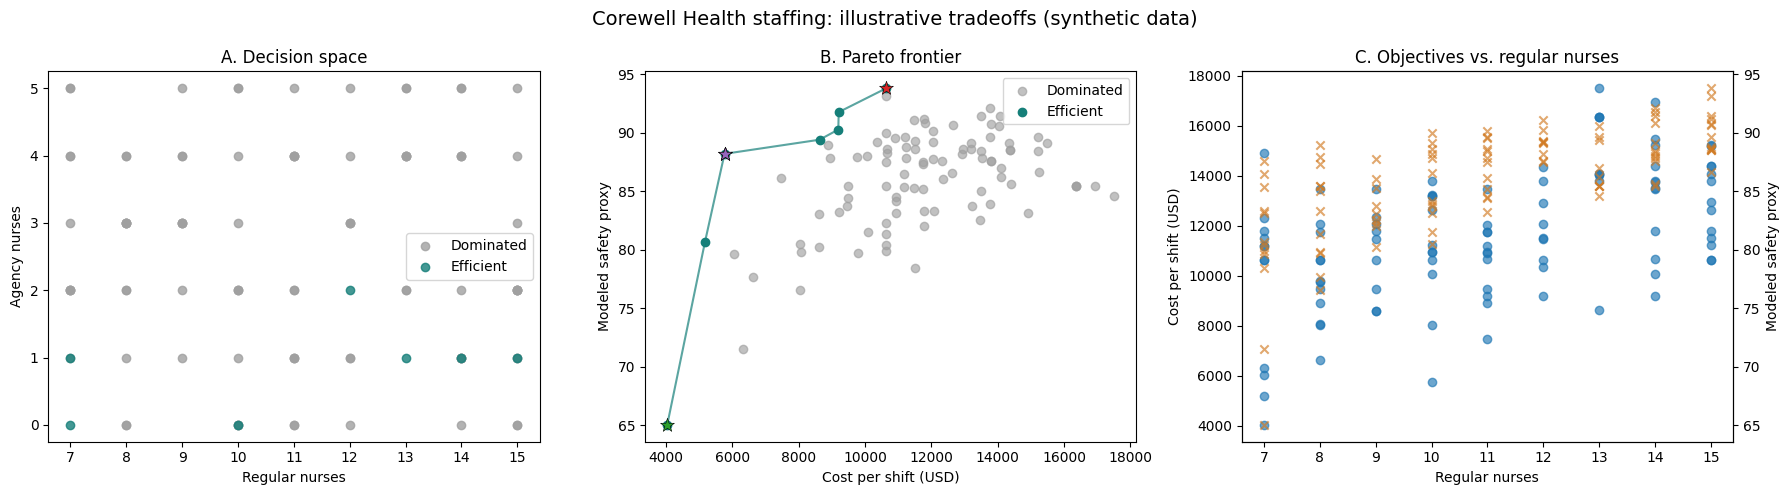

In [7]:
fig,axes=plt.subplots(1,3,figsize=(18,5))
for group,name,color in [(dominated,'Dominated','#a0a0a0'),(front,'Efficient','#157f79')]:
    axes[0].scatter(group.regular_nurses,group.agency_nurses,label=name,color=color,alpha=.8)
axes[0].set(xlabel='Regular nurses',ylabel='Agency nurses',title='A. Decision space');axes[0].legend()
axes[1].scatter(dominated.staffing_cost_usd,dominated.safety_proxy_score,label='Dominated',color='#a0a0a0',alpha=.65)
axes[1].scatter(front.staffing_cost_usd,front.safety_proxy_score,label='Efficient',color='#157f79',zorder=3)
axes[1].plot(front.staffing_cost_usd,front.safety_proxy_score,color='#157f79',alpha=.7)
for name,r in strategies.items():
    axes[1].scatter(r.staffing_cost_usd,r.safety_proxy_score,marker='*',s=110,edgecolor='black',linewidth=.4,zorder=5)
axes[1].set(xlabel='Cost per shift (USD)',ylabel='Modeled safety proxy',title='B. Pareto frontier');axes[1].legend()
axes[2].scatter(df.regular_nurses,df.staffing_cost_usd,label='Cost (USD)',alpha=.65)
ax2=axes[2].twinx();ax2.scatter(df.regular_nurses,df.safety_proxy_score,label='Safety proxy',marker='x',color='#d17a22',alpha=.65)
axes[2].set(xlabel='Regular nurses',ylabel='Cost per shift (USD)',title='C. Objectives vs. regular nurses');ax2.set_ylabel('Modeled safety proxy')
fig.suptitle('Corewell Health staffing: illustrative tradeoffs (synthetic data)',fontsize=14)
fig.tight_layout();fig.savefig(OUT/'three_panel_tradeoffs.png',dpi=180,bbox_inches='tight');plt.show()

## 7. Findings, business implications, and limitations
**Interpretation:** The Pareto frontier identifies scenarios for which no other modeled scenario offers both a lower or equal cost and a higher or equal safety proxy, with at least one strict improvement. Dominated scenarios can be excluded from further *model-based* consideration. The five strategies show how different stakeholder priorities change the recommended hypothetical staffing mix.

**Business implications:** This framework can help structure conversations about overtime, agency staffing, budget pressure, and staffing coverage. However, its outputs **are not recommendations for Corewell Health staffing levels**.

**Limitations:** Synthetic assumptions; no unit acuity, nurse-to-patient ratios, patient census by shift, licensure/skill mix, breaks, state/federal rules, labor contracts, staff fatigue research calibration, or actual adverse-event outcomes. The safety score is not patient safety itself. The equity strategy balances two normalized objectives; it does not measure equitable outcomes across patient groups. Real use would require validated clinical metrics, source-verified rates, constraints, and stakeholder review.

**Next phase:** Add feasibility constraints, validation, and a decision agent; do not implement those yet.